# Sales Forecasting Assessment

This notebook loads the Superstore dataset, aggregates sales by month, and trains a Random Forest Regressor model to forecast future demand. The goal is to provide a clean, interpretable baseline for sales prediction.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings('ignore')

## Data Preparation
First, we load the CSV and parse the order dates. Then, we aggregate the daily sales data into monthly totals to reduce noise and make the overall trend easier to see.

In [12]:
# Load data
df = pd.read_csv('Sample - Superstore.csv', encoding='latin-1')

df['Order Date'] = pd.to_datetime(df['Order Date'])
df = df[['Order Date', 'Sales']]

# Aggregate to monthly sales
monthly_sales = df.resample('ME', on='Order Date').sum().reset_index()
monthly_sales.head()

,Order Date,Sales
0,2014-01-31,14236.895
1,2014-02-28,4519.892
2,2014-03-31,55691.009
3,2014-04-30,28295.345
4,2014-05-31,23648.287


## Feature Engineering
We need numerical features for our regression model. `Time_Index` represents the overall trend over time, and a `Month` feature (1-12) to help the model pick up on yearly seasonality.

In [13]:
monthly_sales['Time_Index'] = np.arange(len(monthly_sales))
monthly_sales['Month'] = monthly_sales['Order Date'].dt.month

monthly_sales.head()

,Order Date,Sales,Time_Index,Month
0,2014-01-31,14236.895,0,1
1,2014-02-28,4519.892,1,2
2,2014-03-31,55691.009,2,3
3,2014-04-30,28295.345,3,4
4,2014-05-31,23648.287,4,5


## Model Training
We will split the data, keeping the last 6 months as a test set. We'll fit a Random Forest Regressor model on the training data.

In [16]:
X = monthly_sales[['Time_Index', 'Month']]
y = monthly_sales['Sales']

test_size = 6
train_size = len(monthly_sales) - test_size

X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
print('Model fitted.')

Model fitted.


## Evaluation
Let's see how the model performed on the hold-out test set using MAE and RMSE.

In [17]:
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f'MAE: {mae:.2f}')
print(f'RMSE: {rmse:.2f}')

MAE: 13789.20
RMSE: 16664.58


## Forecasting Future Sales
Now we'll use the trained model to predict sales for the next 12 months.

In [18]:
last_date = monthly_sales['Order Date'].max()
future_dates = pd.date_range(start=last_date + pd.offsets.MonthEnd(1), periods=12, freq='ME')

future_X = pd.DataFrame({
    'Time_Index': np.arange(len(monthly_sales), len(monthly_sales) + 12),
    'Month': future_dates.month
})

future_predictions = model.predict(future_X)
future_sales_df = pd.DataFrame({'Date': future_dates, 'Predicted_Sales': future_predictions})
future_sales_df

,Date,Predicted_Sales
0,2018-01-31,36572.642408
1,2018-02-28,29975.909770
2,2018-03-31,53685.811208
3,2018-04-30,46686.722667
4,2018-05-31,49056.003182
5,2018-06-30,49410.635801
6,2018-07-31,45767.302525
7,2018-08-31,43929.210298
8,2018-09-30,72931.123085
9,2018-10-31,66300.571926


## Visualization
Finally, we plot the historical data alongside our 12-month forecast.

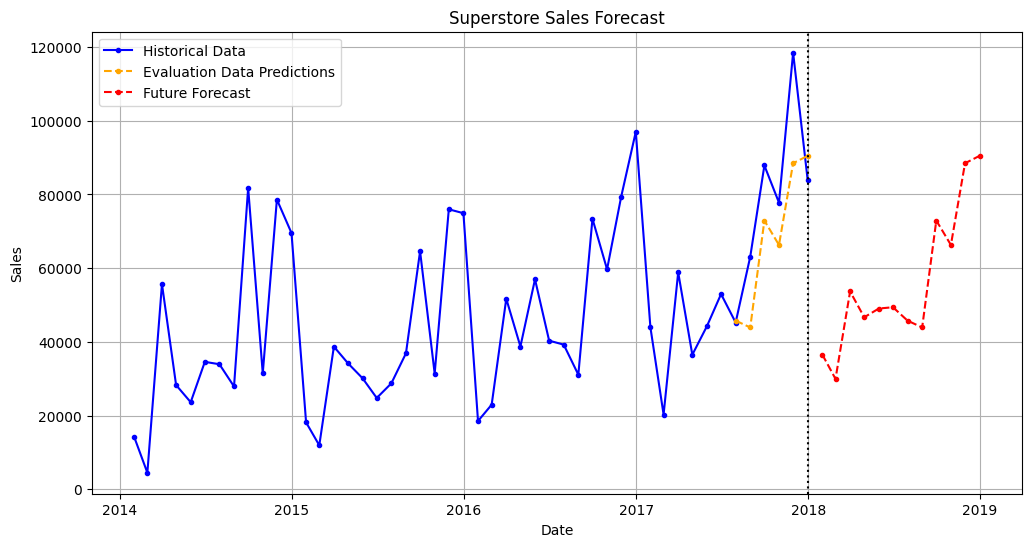

In [20]:
plt.figure(figsize=(12, 6))

plt.plot(monthly_sales['Order Date'], monthly_sales['Sales'], label='Historical Data', color='blue', marker='.')

test_dates = monthly_sales['Order Date'].iloc[train_size:]
plt.plot(test_dates, y_pred, label='Evaluation Data Predictions', color='orange', linestyle='--', marker='.')

plt.plot(future_sales_df['Date'], future_sales_df['Predicted_Sales'], label='Future Forecast', color='red', linestyle='--', marker='.')

plt.title('Superstore Sales Forecast')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.axvline(x=last_date, color='black', linestyle=':', label='Forecast Start')

plt.show()


## Summary
The model successfully captures the basic seasonality (yearly spikes) and overall trend. The forecast chart can be used to roughly estimate inventory needs or expected cash flow for the upcoming year.